# Can ARIMA beat a naive baseline? Leakage-free forecast evaluation on financial returns

**Question.** Does an ARIMA model add measurable one-step-ahead accuracy over trivial benchmarks on daily equity returns, and can the diagnostics tell us the answer *before* we fit anything?

**Approach.**
1. Diagnose the series: non-stationary prices, stationary returns, volatility clustering (ADF, ACF/PACF, Ljung-Box, ARCH-LM, EWMA volatility).
2. Select ARIMA order by AIC on **training data only**.
3. Evaluate with **walk-forward (rolling-origin) validation**: every forecast uses only data available at that date. A built-in test checks this.
4. Judge against benchmarks (zero-change, rolling mean) with MAE, RMSE, WAPE, bias, MASE, directional accuracy and a **Diebold-Mariano test**, not just point estimates.
5. Add **probabilistic forecasts**: conformal prediction intervals, with and without volatility scaling, checked for coverage overall and by volatility regime.
6. Repeat the same pipeline on a strongly autocorrelated series as a contrast.

All commentary in the results sections is computed from the data that was actually loaded. The final summary cell prints the numbers it quotes, together with the data source.

| Section | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Data |
| 2-3 | Prices, returns and stationarity |
| 4 | Rolling statistics |
| 5 | Autocorrelation (ACF/PACF) |
| 6 | Volatility clustering |
| 7 | Model selection (training data only) |
| 8 | Walk-forward validation and benchmarks |
| 9 | Residual diagnostics |
| 10 | Probabilistic forecasts (conformal intervals) |
| 11 | Contrast: a series where ARIMA should help |
| 12 | Results summary, limitations, next steps |

## 0. Setup and configuration
Every choice that affects results is defined here, so a run can be reproduced and audited.

In [1]:
import warnings
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.grid": True, "grid.alpha": .3})

# ---- configuration ----
TICKER, START = "SPY", "2018-01-01"
USE_REAL = True           # False forces the simulated GARCH demo series
SEED = 2026
TRAIN_FRAC = 0.80         # chronological split, no shuffling
WINDOW = 750              # rolling estimation window (trading days)
REFIT_EVERY = 21          # re-estimate parameters about monthly; update the filter daily
EWMA_LAMBDA = 0.94        # RiskMetrics decay factor
ALPHAS = (0.20, 0.10)     # nominal miscoverage -> 80% and 90% prediction intervals
CAL_WINDOW, CAL_MIN = 250, 100   # conformal calibration window / minimum calibration size

rng = np.random.default_rng(SEED)

## 1. Data
The loader tries, in order: (1) a fresh download from Yahoo Finance via `yfinance`, (2) a cached CSV in `data/`, (3) a **simulated GARCH(1,1)** series, used only so the notebook still runs offline.
The data source is recorded in `DATA_SOURCE` and printed in the final summary. Results from simulated data must not be reported as results on real prices.

Data source: Yahoo Finance via yfinance (SPY), downloaded 2026-10-14
2208 observations, 2018-01-02 to 2026-10-14


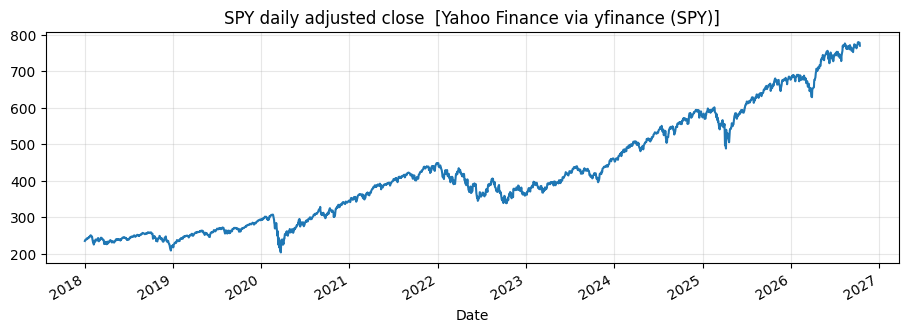

In [2]:
def simulate_garch(n=2200, omega=1e-6, alpha=0.08, beta=0.90, mu=0.0004, seed=SEED):
    g = np.random.default_rng(seed)
    r = np.zeros(n); s2 = np.zeros(n); s2[0] = omega / (1 - alpha - beta)
    z = g.standard_t(6, n) / np.sqrt(6 / 4)                   # fat-tailed, unit-variance shocks
    for t in range(1, n):
        s2[t] = omega + alpha * (r[t-1] - mu) ** 2 + beta * s2[t-1]
        r[t] = mu + np.sqrt(s2[t]) * z[t]
    idx = pd.bdate_range("2018-01-02", periods=n)
    return pd.Series(100 * np.exp(np.cumsum(r)), index=idx, name="price")

def load_prices():
    cache = Path("data") / f"{TICKER}_close.csv"
    if USE_REAL:
        try:
            import yfinance as yf
            df = yf.download(TICKER, start=START, auto_adjust=True, progress=False)
            s = df["Close"].squeeze().dropna().rename("price")
            if len(s) > 1000:
                cache.parent.mkdir(exist_ok=True); s.to_csv(cache)
                return s, f"Yahoo Finance via yfinance ({TICKER}), downloaded {date.today()}"
        except Exception as e:
            print("Download failed:", type(e).__name__, e)
        if cache.exists():
            s = pd.read_csv(cache, index_col=0, parse_dates=True).squeeze("columns").rename("price")
            return s, f"cached CSV {cache} ({TICKER})"
    print("\n" + "!" * 78 + "\n!! USING SIMULATED DATA: results below are a demo, not results on real prices !!\n" + "!" * 78 + "\n")
    return simulate_garch(), "SIMULATED GARCH(1,1) (demo only)"

price, DATA_SOURCE = load_prices()
print("Data source:", DATA_SOURCE)
print(f"{len(price)} observations, {price.index[0].date()} to {price.index[-1].date()}")
price.plot(title=f"{TICKER} daily adjusted close  [{DATA_SOURCE.split(',')[0]}]"); plt.show()

## 2. Prices behave like a random walk
For a random walk $X_n = \xi_1 + \dots + \xi_n$ with i.i.d. steps, three facts matter here:
- Increments over disjoint blocks are independent, so past returns should say little about future returns.
- $\mathrm{Var}(X_n)$ grows with $n$, so the series is **not stationary**.
- Differencing recovers the i.i.d. steps, which is why we model returns rather than prices.

A quick simulation confirms the variance growth, then we test the actual price series.

n= 10  empirical Var(X_n) =   10.00   theory = 10
n= 50  empirical Var(X_n) =   49.62   theory = 50
n=100  empirical Var(X_n) =   99.41   theory = 100

ADF on price: p = 0.994 -> cannot reject a unit root (non-stationary)


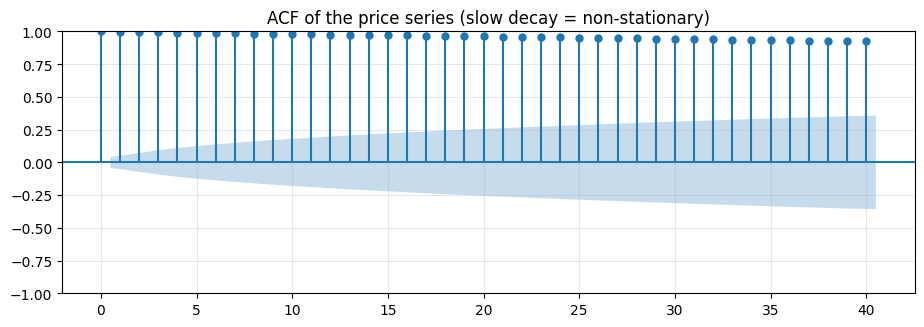

In [3]:
walks = np.cumsum(rng.choice([-1, 1], size=(20000, 100)), axis=1)
for n_ in (10, 50, 100):
    print(f"n={n_:3d}  empirical Var(X_n) = {walks[:, n_-1].var():7.2f}   theory = {n_}")

adf_p = adfuller(price)[1]
print(f"\nADF on price: p = {adf_p:.3f} -> " + ("reject unit root" if adf_p < 0.05 else "cannot reject a unit root (non-stationary)"))
plot_acf(price, lags=40); plt.title("ACF of the price series (slow decay = non-stationary)"); plt.show()

## 3. Return transformations
- **Simple return** $R_t = (P_t - P_{t-1})/P_{t-1}$
- **Log return** $r_t = \ln P_t - \ln P_{t-1}$, which adds across time and is close to $R_t$ when returns are small.

ARIMA$(p,1,q)$ on log price is the same as ARMA$(p,q)$ on log returns, so we work with log returns and set $d=0$.

           simple         log
count  2207.00000  2207.00000
mean      0.00061     0.00054
std       0.01195     0.01198
min      -0.10942    -0.11589
25%      -0.00428    -0.00429
50%       0.00079     0.00079
75%       0.00648     0.00646
max       0.10502     0.09986

max |simple - log| = 0.00646
ADF on log returns: p = 1.13e-27
Excess kurtosis = 13.69 (normal = 0);  Jarque-Bera p = 0.00e+00


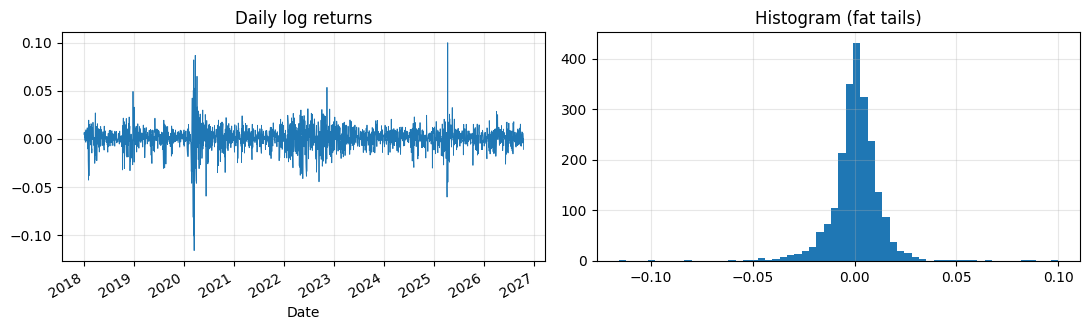

In [4]:
log_price = np.log(price)
simple_ret = price.pct_change().dropna()
log_ret = log_price.diff().dropna()

print(pd.DataFrame({"simple": simple_ret.describe(), "log": log_ret.describe()}).round(5))
print(f"\nmax |simple - log| = {(simple_ret - log_ret).abs().max():.5f}")
print(f"ADF on log returns: p = {adfuller(log_ret)[1]:.2e}")
print(f"Excess kurtosis = {stats.kurtosis(log_ret):.2f} (normal = 0);  Jarque-Bera p = {stats.jarque_bera(log_ret)[1]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
log_ret.plot(ax=ax[0], lw=.6, title="Daily log returns"); log_ret.hist(bins=60, ax=ax[1]); ax[1].set_title("Histogram (fat tails)")
plt.tight_layout(); plt.show()

## 4. Rolling statistics
A stationary series has constant mean and variance. Rolling estimates (63-day mean, 21- and 63-day volatility, annualized with $\sqrt{252}$) show whether that holds.

Whole-sample mean = 0.00054, daily std = 0.0120


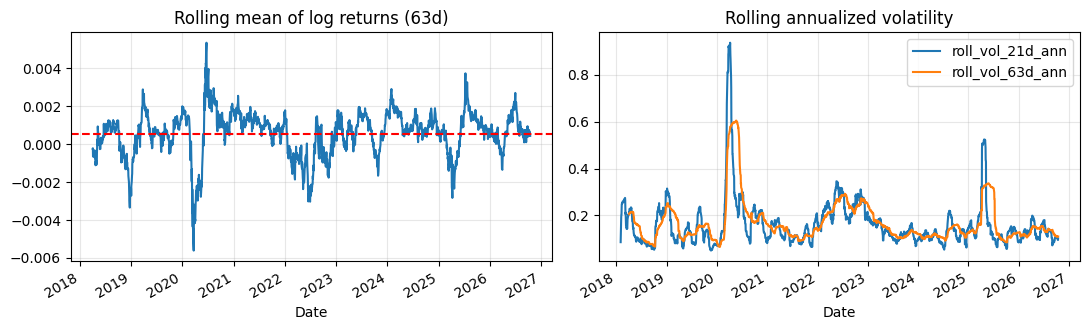

63d annualized volatility ranges from 6.6% to 60.4% (median 14.2%)


In [5]:
full_mean, full_var = log_ret.mean(), log_ret.var(ddof=1)
print(f"Whole-sample mean = {full_mean:.5f}, daily std = {np.sqrt(full_var):.4f}")

roll = pd.DataFrame({"roll_mean_63d": log_ret.rolling(63).mean(),
                     "roll_vol_21d_ann": log_ret.rolling(21).std() * np.sqrt(252),
                     "roll_vol_63d_ann": log_ret.rolling(63).std() * np.sqrt(252)})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
roll["roll_mean_63d"].plot(ax=ax[0], title="Rolling mean of log returns (63d)"); ax[0].axhline(full_mean, color="r", ls="--")
roll[["roll_vol_21d_ann", "roll_vol_63d_ann"]].plot(ax=ax[1], title="Rolling annualized volatility")
plt.tight_layout(); plt.show()

vol = roll["roll_vol_63d_ann"].dropna()
print(f"63d annualized volatility ranges from {vol.min():.1%} to {vol.max():.1%} (median {vol.median():.1%})")

## 5. Autocorrelation (ACF and PACF)
- **ACF** $\hat\rho(k)$ measures linear dependence at lag $k$. **PACF** removes the effect of lags $1..k-1$ (Durbin-Levinson recursion).
- Under white noise, about 95% of $\hat\rho(k)$ lie within $\pm 1.96/\sqrt n$.
- **Ljung-Box** tests all autocorrelations up to lag $m$ jointly. It assumes constant variance, so it over-rejects when volatility clusters (Section 6).

The ACF and PACF are implemented from scratch and checked against `statsmodels`.

From-scratch ACF and PACF match statsmodels.


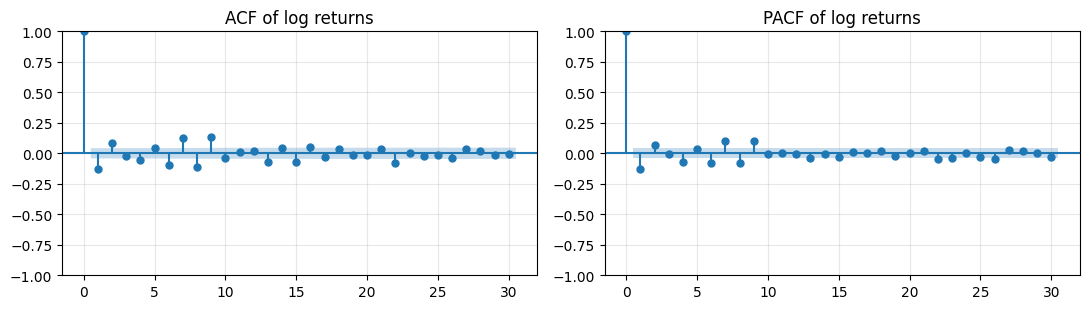

95% white-noise band = +/-0.042; largest |ACF| over lags 1-20 = 0.130 (lag 1)
     lb_stat  lb_pvalue
5    66.6422        0.0
10  193.3886        0.0
20  234.1591        0.0


In [6]:
def acvf_manual(x, K=20):
    x = np.asarray(x, float); n = len(x); xc = x - x.mean()
    return np.array([np.sum(xc[:n-k] * xc[k:]) / n for k in range(K + 1)])

def durbin_levinson(rho, K):
    """PACF from ACF values rho[0..K]."""
    phi = np.zeros((K + 1, K + 1)); out = [rho[1]]; phi[1, 1] = rho[1]
    for k in range(2, K + 1):
        num = rho[k] - sum(phi[k-1, j] * rho[k-j] for j in range(1, k))
        den = 1 - sum(phi[k-1, j] * rho[j] for j in range(1, k))
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k-1, j] - phi[k, k] * phi[k-1, k-j]
        out.append(phi[k, k])
    return np.array(out)

g = acvf_manual(log_ret, 20); rho = g / g[0]
assert np.allclose(rho, acf(log_ret, nlags=20, fft=False)), "ACF mismatch"
assert np.allclose(durbin_levinson(rho, 20), pacf(log_ret, nlags=20, method="ywm")[1:]), "PACF mismatch"
print("From-scratch ACF and PACF match statsmodels.")

def acf_pacf_plot(x, lags=30, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    plot_acf(x, lags=lags, ax=ax[0], title=f"ACF {title}")
    plot_pacf(x, lags=lags, ax=ax[1], method="ywm", title=f"PACF {title}")
    plt.tight_layout(); plt.show()

acf_pacf_plot(log_ret, title="of log returns")
band = 1.96 / np.sqrt(len(log_ret))
a20 = acf(log_ret, nlags=20, fft=False)[1:]
k_max = int(np.abs(a20).argmax()) + 1
print(f"95% white-noise band = +/-{band:.3f}; largest |ACF| over lags 1-20 = {np.abs(a20).max():.3f} (lag {k_max})")
print(acorr_ljungbox(log_ret, lags=[5, 10, 20]).round(4))

**Robustness check.** A few extreme days can dominate sample autocorrelation. The cell below recomputes the lag-1 autocorrelation with the Feb-Jun 2020 stress period removed, to see how much of it comes from that episode.

In [7]:
r1_all = acf(log_ret, nlags=1, fft=False)[1]
mask = ~((log_ret.index >= "2020-02-15") & (log_ret.index <= "2020-06-30"))
r1_ex = acf(log_ret[mask], nlags=1, fft=False)[1]
print(f"Lag-1 autocorrelation, full sample        : {r1_all:+.3f}")
print(f"Lag-1 autocorrelation, excl. Feb-Jun 2020 : {r1_ex:+.3f}   ({mask.sum()} of {len(mask)} days kept)")

Lag-1 autocorrelation, full sample        : -0.130
Lag-1 autocorrelation, excl. Feb-Jun 2020 : -0.033   (2113 of 2207 days kept)


## 6. Volatility clustering
Returns can be (nearly) uncorrelated yet not independent: large moves follow large moves. The diagnostic is the ACF of **squared** returns, plus an ARCH-LM test for conditional heteroskedasticity.

We also build an **EWMA** variance forecast, $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda) r_{t-1}^2$ with $\lambda = 0.94$. It uses only information up to $t-1$, so it is a legitimate forecast of day $t$'s variance and is used for the interval scaling in Section 10.

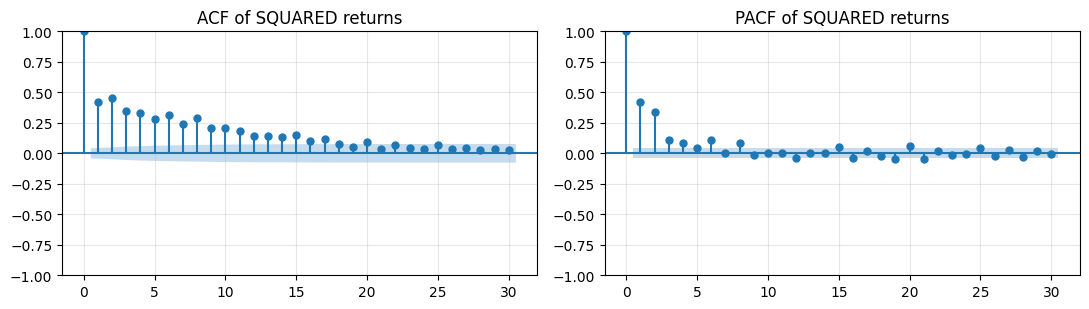

Ljung-Box on squared returns:
      lb_stat  lb_pvalue
5   1524.8068        0.0
10  2245.0329        0.0
20  2590.4665        0.0
ARCH-LM test (10 lags): statistic = 655.6, p = 2.10e-134


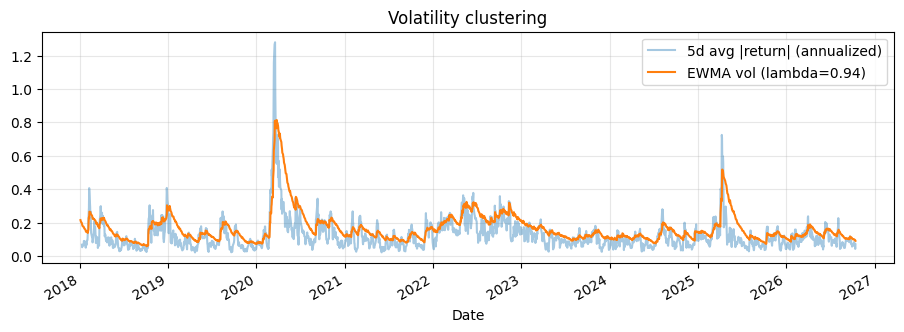

In [8]:
acf_pacf_plot(log_ret ** 2, title="of SQUARED returns")
print("Ljung-Box on squared returns:"); print(acorr_ljungbox(log_ret ** 2, lags=[5, 10, 20]).round(4))
lm, lm_p, _, _ = het_arch(log_ret - log_ret.mean(), nlags=10)
print(f"ARCH-LM test (10 lags): statistic = {lm:.1f}, p = {lm_p:.2e}")

def ewma_variance(r, lam=EWMA_LAMBDA):
    """v[t] = variance forecast for day t using returns up to t-1 only."""
    r = np.asarray(r, float); v = np.empty(len(r)); v[0] = np.var(r[:30])
    for t in range(1, len(r)):
        v[t] = lam * v[t-1] + (1 - lam) * r[t-1] ** 2
    return v

ewma_var = ewma_variance(log_ret.values)
ewma_vol_ann = pd.Series(np.sqrt(ewma_var * 252), index=log_ret.index)
ax = (log_ret.abs() * np.sqrt(252)).rolling(5).mean().plot(alpha=.4, label="5d avg |return| (annualized)")
ewma_vol_ann.plot(ax=ax, label=f"EWMA vol (lambda={EWMA_LAMBDA})"); ax.legend(); ax.set_title("Volatility clustering"); plt.show()

## 7. Model selection (training data only)
The chronological split gives the first 80% for training and the last 20% for testing. Orders are compared by **AIC** (and BIC for reference) on the training set only. Choosing the order with test data would be look-ahead bias.

In [9]:
split = int(len(log_ret) * TRAIN_FRAC)
assert split >= WINDOW, f"training span ({split}) shorter than WINDOW ({WINDOW})"
train, test = log_ret.iloc[:split], log_ret.iloc[split:]
print(f"train: {len(train)} days ({train.index[0].date()} to {train.index[-1].date()}),  test: {len(test)} days ({test.index[0].date()} to {test.index[-1].date()})")

def ic_grid(y, pmax=3, qmax=3, d=0):
    rows = []
    for p in range(pmax + 1):
        for q in range(qmax + 1):
            try:
                r = ARIMA(np.asarray(y), order=(p, d, q)).fit()
                rows.append((p, d, q, r.aic, r.bic))
            except Exception:
                pass
    return pd.DataFrame(rows, columns=["p", "d", "q", "AIC", "BIC"]).sort_values("AIC").reset_index(drop=True)

grid = ic_grid(train)
print(grid.head(6).round(2))
best = tuple(grid.loc[0, ["p", "d", "q"]].astype(int))
best_bic = tuple(grid.sort_values("BIC").iloc[0][["p", "d", "q"]].astype(int))
gap = grid.loc[1, "AIC"] - grid.loc[0, "AIC"]
print(f"\nSelected by AIC: {best};  by BIC: {best_bic};  AIC gap to runner-up: {gap:.2f}")
res = ARIMA(np.asarray(train), order=best).fit(); print(res.summary().tables[1])

train: 1765 days (2018-01-03 to 2025-01-08),  test: 442 days (2025-01-10 to 2026-10-14)
   p  d  q       AIC       BIC
0  0  0  2 -10551.49 -10529.59
1  2  0  0 -10550.89 -10528.99
2  0  0  3 -10550.48 -10523.10
3  3  0  0 -10549.13 -10521.75
4  2  0  1 -10548.72 -10521.34
5  1  0  3 -10548.33 -10515.47

Selected by AIC: (0, 0, 2);  by BIC: (0, 0, 2);  AIC gap to runner-up: 0.60
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      1.683      0.092   -8.33e-05       0.001
ma.L1         -0.1226      0.011    -11.103      0.000      -0.144      -0.101
ma.L2          0.0829      0.010      8.704      0.000       0.064       0.102
sigma2         0.0001    2.1e-06     70.154      0.000       0.000       0.000


**How to read this.** If the top candidates are within a couple of AIC points, the preference is weak and a simpler order is more defensible. Mixed AR and MA terms with similar size and opposite sign partly cancel, which suggests over-parameterization. Significant in-sample coefficients do not prove better forecasts. Only out-of-sample evaluation can show that, as in the next section.

## 8. Walk-forward validation and benchmarks
For each test day $t$:
1. take the most recent `WINDOW` observations strictly before $t$,
2. use parameters estimated on a recent window (re-estimated every `REFIT_EVERY` days) and filter through the latest data,
3. forecast one step ahead, then reveal the true value and move on.

**Benchmarks.** *Zero* (the random-walk forecast: no change) and the *rolling mean* of the window.

**Metrics.** MAE and RMSE (return units); **WAPE** $=\sum|e|/\sum|y|$ (1.0 equals the zero forecast's WAPE); **bias** (mean of forecast minus actual); **MASE** (MAE scaled by the in-sample one-step naive MAE, below 1 beats the naive forecast); **directional accuracy**. **Diebold-Mariano** tests whether the squared-error difference between two forecasts is distinguishable from zero. MAPE is omitted because it is unstable when actual returns are near zero.

In [10]:
def rolling_arima(y, order, window, start, refit_every=REFIT_EVERY, end=None):
    """One-step-ahead forecasts of y[start:end] using only data BEFORE each forecast date."""
    y = np.asarray(y, float); end = len(y) if end is None else end
    preds, res_ = [], None
    for i in range(start, end):
        if res_ is None or (i - start) % refit_every == 0:
            res_ = ARIMA(y[i-window:i], order=order).fit()           # re-estimate on the latest window
        preds.append(float(res_.apply(y[i-window:i], refit=False).forecast(1)[0]))   # fixed params, new data
    return np.array(preds)

def rolling_mean_bench(y, window, start):
    y = np.asarray(y, float); return np.array([y[i-window:i].mean() for i in range(start, len(y))])

def forecast_metrics(actual, pred, name, mase_scale, prev=0.0):
    e = actual - pred
    dir_acc = np.mean(np.sign(actual - prev) == np.sign(pred - prev)) if np.any(pred != prev) else np.nan
    return {"model": name, "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "WAPE": np.sum(np.abs(e)) / np.sum(np.abs(actual)), "Bias": np.mean(pred - actual),
            "MASE": np.mean(np.abs(e)) / mase_scale, "Dir. acc.": dir_acc}

def dm_test(e_model, e_bench):
    """Diebold-Mariano test, squared-error loss, horizon 1 (Harvey small-sample correction).
    Positive statistic = the model has LARGER squared errors than the benchmark."""
    d = np.asarray(e_model) ** 2 - np.asarray(e_bench) ** 2
    n = len(d); stat = d.mean() / np.sqrt(d.var(ddof=1) / n) * np.sqrt((n - 1) / n)
    return stat, 2 * (1 - stats.t.cdf(abs(stat), n - 1))

# ---- leakage check: scrambling the 'future' must not change earlier forecasts ----
def check_no_lookahead(y, order, window, start, n_check=15):
    y1 = np.asarray(y, float).copy(); y2 = y1.copy()
    y2[start + n_check:] = np.random.default_rng(0).normal(0, y1.std(), len(y2) - start - n_check)
    p1 = rolling_arima(y1, order, window, start, end=start + n_check + 10)
    p2 = rolling_arima(y2, order, window, start, end=start + n_check + 10)
    assert np.allclose(p1[:n_check], p2[:n_check]), "LEAKAGE: forecasts depend on future observations"
    assert not np.allclose(p1[n_check:], p2[n_check:]), "sanity check failed: scrambling had no effect"
    print(f"No-lookahead check passed: the first {n_check} forecasts are identical when all later data is replaced by noise.")

y = log_ret.values
check_no_lookahead(y, best, WINDOW, split)

No-lookahead check passed: the first 15 forecasts are identical when all later data is replaced by noise.


In [11]:
start = split
pred_arima = rolling_arima(y, best, WINDOW, start)
pred_zero = np.zeros(len(y) - start)
pred_mean = rolling_mean_bench(y, WINDOW, start)
actual = y[start:]
scale = np.mean(np.abs(np.diff(y[:start])))                    # in-sample one-step naive MAE

names = [f"ARIMA{best}", "Zero (random walk)", "Rolling mean"]
tab = pd.DataFrame([forecast_metrics(actual, p, n, scale) for p, n in zip([pred_arima, pred_zero, pred_mean], names)]).set_index("model")
tab["Rel. RMSE vs zero"] = tab["RMSE"] / tab.loc["Zero (random walk)", "RMSE"]
print(f"Walk-forward results on {len(actual)} out-of-sample days ({test.index[0].date()} to {test.index[-1].date()})")
print(tab.round(5))

e_arima, e_zero, e_mean = actual - pred_arima, actual - pred_zero, actual - pred_mean
dm_rows = []
for a, b, la, lb in [(e_arima, e_zero, "ARIMA", "Zero"), (e_arima, e_mean, "ARIMA", "Rolling mean"), (e_mean, e_zero, "Rolling mean", "Zero")]:
    s, p = dm_test(a, b); dm_rows.append({"comparison": f"{la} vs {lb}", "DM stat": s, "p-value": p})
dm_tab = pd.DataFrame(dm_rows).set_index("comparison")
print("\nDiebold-Mariano tests (positive = first model worse):"); print(dm_tab.round(4))
dm_arima_zero_p = dm_tab.loc["ARIMA vs Zero", "p-value"]; rel_rmse_arima = tab.loc[names[0], "Rel. RMSE vs zero"]

Walk-forward results on 442 out-of-sample days (2025-01-10 to 2026-10-14)
                        MAE     RMSE     WAPE     Bias     MASE  Dir. acc.  \
model                                                                        
ARIMA(0, 0, 2)      0.00693  0.01063  1.00090  0.00003  0.58435    0.52262   
Zero (random walk)  0.00693  0.01062  1.00000 -0.00065  0.58382        NaN   
Rolling mean        0.00689  0.01060  0.99544  0.00004  0.58116    0.54299   

                    Rel. RMSE vs zero  
model                                  
ARIMA(0, 0, 2)                1.00078  
Zero (random walk)            1.00000  
Rolling mean                  0.99852  

Diebold-Mariano tests (positive = first model worse):
                       DM stat  p-value
comparison                             
ARIMA vs Zero           0.2158   0.8292
ARIMA vs Rolling mean   0.9881   0.3236
Rolling mean vs Zero   -0.6026   0.5471


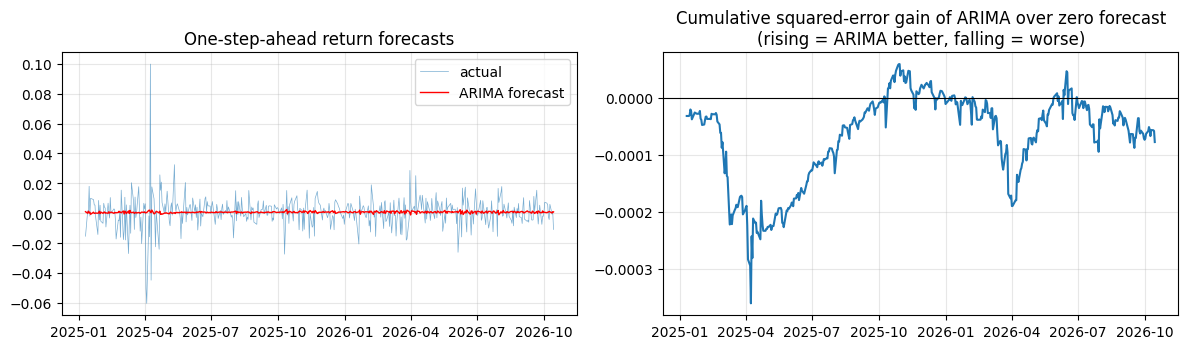

In [12]:
idx_t = log_ret.index[start:]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(idx_t, actual, lw=.5, alpha=.6, label="actual"); ax[0].plot(idx_t, pred_arima, color="r", lw=1, label="ARIMA forecast")
ax[0].legend(); ax[0].set_title("One-step-ahead return forecasts")
cum_gain = np.cumsum(e_zero ** 2 - e_arima ** 2)
ax[1].plot(idx_t, cum_gain); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Cumulative squared-error gain of ARIMA over zero forecast\n(rising = ARIMA better, falling = worse)")
plt.tight_layout(); plt.show()

**Reading the results.** A relative RMSE near 1 with a non-significant Diebold-Mariano p-value means the model is not distinguishable from the benchmark. Directional accuracy above 50% can simply reflect positive drift (more up days than down days), which the rolling-mean benchmark captures too. The cumulative-gain plot shows whether any advantage is persistent or comes from a single episode.

## 9. Residual diagnostics
If the model has captured the linear structure, residuals should look like white noise. Plain Ljung-Box is distorted by volatility clustering, so we also test **standardized** residuals (residual divided by the EWMA volatility forecast) and adjust the degrees of freedom for the fitted parameters.

In [13]:
resid = pd.Series(res.resid)
std_resid = resid.values / np.sqrt(ewma_var[:len(resid)])
p_q = best[0] + best[2]
lb = lambda x, **kw: acorr_ljungbox(x, lags=[10], **kw)["lb_pvalue"].iloc[0]
print(f"Ljung-Box (10 lags) on residuals            : p = {lb(resid, model_df=p_q):.4f}")
print(f"Ljung-Box (10 lags) on standardized resid.  : p = {lb(std_resid, model_df=p_q):.4f}")
print(f"Ljung-Box (10 lags) on squared residuals    : p = {lb(resid ** 2):.2e}")
print(f"ARCH-LM (10 lags) on residuals              : p = {het_arch(resid.values, nlags=10)[1]:.2e}")

Ljung-Box (10 lags) on residuals            : p = 0.0000
Ljung-Box (10 lags) on standardized resid.  : p = 0.0000
Ljung-Box (10 lags) on squared residuals    : p = 0.00e+00
ARCH-LM (10 lags) on residuals              : p = 1.80e-114


**Reading the results.** A small p-value on the raw residuals can come from heteroskedasticity rather than leftover linear structure. The standardized-residual test separates the two. Small p-values on the squared residuals and ARCH-LM mean the variance structure remains, which a mean model like ARIMA cannot fix (the next section handles it through the interval width).

## 10. Probabilistic forecasts: conformal prediction intervals
A point forecast alone hides uncertainty, and downstream planning models need ranges. We build one-step intervals around the ARIMA forecast with **split-conformal** calibration on a rolling window of *past* forecast errors only:

- **Constant width:** interval $\hat y_t \pm q$, where $q$ is the $(1-\alpha)$ quantile of recent absolute errors.
- **Volatility-scaled:** interval $\hat y_t \pm q\,\hat\sigma_t$, where $q$ is the quantile of recent *standardized* errors $|e_j|/\hat\sigma_j$ and $\hat\sigma_t$ is the EWMA volatility forecast.

We check **coverage** (does the nominal 90% interval contain about 90% of outcomes?), **coverage by volatility regime** (terciles of $\hat\sigma_t$), mean width, and the **interval score** (lower is better; it penalizes width and misses).

In [14]:
sigma_test = np.sqrt(ewma_var[start:])

def conformal_intervals(actual, pred, sigma, alpha, scaled, cal_window=CAL_WINDOW, cal_min=CAL_MIN):
    m = len(actual); lo = np.full(m, np.nan); hi = np.full(m, np.nan)
    err = np.abs(actual - pred); score = err / sigma if scaled else err
    for k in range(cal_min, m):
        s = score[max(0, k - cal_window):k]                       # only PAST scores
        n = len(s); level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
        q = np.quantile(s, level, method="higher")
        w = q * sigma[k] if scaled else q
        lo[k], hi[k] = pred[k] - w, pred[k] + w
    return lo, hi

def interval_score(y_, lo, hi, alpha):
    return (hi - lo) + (2 / alpha) * np.maximum(lo - y_, 0) + (2 / alpha) * np.maximum(y_ - hi, 0)

ok = np.arange(len(actual)) >= CAL_MIN
terc = np.quantile(sigma_test[ok], [1/3, 2/3]); regime = np.digitize(sigma_test, terc)   # 0 low, 1 mid, 2 high
rows, bands = [], {}
for alpha in ALPHAS:
    for scaled in (False, True):
        lo, hi = conformal_intervals(actual, pred_arima, sigma_test, alpha, scaled)
        cov = (actual >= lo) & (actual <= hi)
        rows.append({"nominal": f"{1-alpha:.0%}", "method": "vol-scaled" if scaled else "constant width",
                     "coverage": cov[ok].mean(), "cov. low vol": cov[ok & (regime == 0)].mean(),
                     "cov. mid vol": cov[ok & (regime == 1)].mean(), "cov. high vol": cov[ok & (regime == 2)].mean(),
                     "mean width": (hi - lo)[ok].mean(), "interval score": interval_score(actual, lo, hi, alpha)[ok].mean()})
        bands[(alpha, scaled)] = (lo, hi)
cov_tab = pd.DataFrame(rows).set_index(["nominal", "method"])
print(f"Evaluated on {ok.sum()} out-of-sample days (first {CAL_MIN} used for calibration only)")
print(cov_tab.round(4))

Evaluated on 342 out-of-sample days (first 100 used for calibration only)
                        coverage  cov. low vol  cov. mid vol  cov. high vol  \
nominal method                                                                
80%     constant width    0.8538        0.8860        0.8246         0.8509   
        vol-scaled        0.7982        0.7719        0.7632         0.8596   
90%     constant width    0.9386        0.9649        0.9561         0.8947   
        vol-scaled        0.9123        0.9035        0.8947         0.9386   

                        mean width  interval score  
nominal method                                      
80%     constant width      0.0220          0.0296  
        vol-scaled          0.0176          0.0280  
90%     constant width      0.0332          0.0379  
        vol-scaled          0.0272          0.0354  


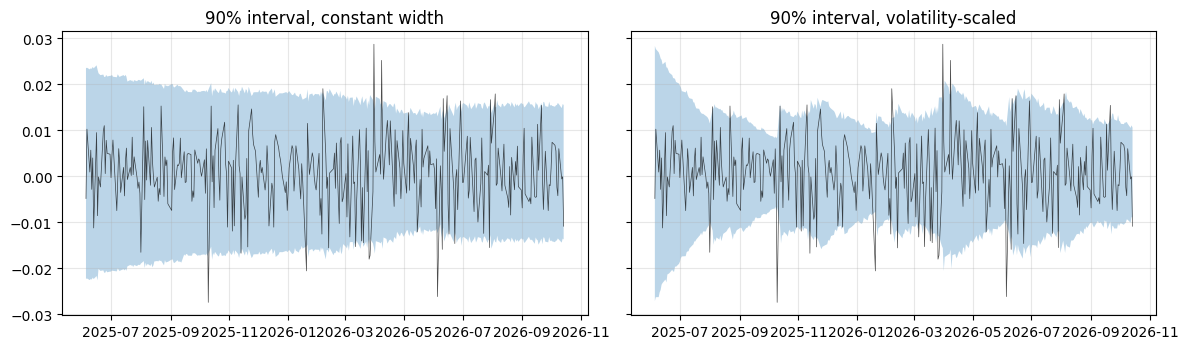

In [15]:
lo, hi = bands[(0.10, True)]; lo_c, hi_c = bands[(0.10, False)]
sl = slice(CAL_MIN, None)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a_, (l_, h_), ttl in zip(ax, [(lo_c, hi_c), (lo, hi)], ["90% interval, constant width", "90% interval, volatility-scaled"]):
    a_.plot(idx_t[sl], actual[sl], lw=.5, color="k", alpha=.7)
    a_.fill_between(idx_t[sl], l_[sl], h_[sl], alpha=.3); a_.set_title(ttl)
plt.tight_layout(); plt.show()

**Reading the results.** Constant-width intervals can hit the nominal overall coverage but are too narrow in turbulent periods and too wide in calm ones, which shows up as uneven coverage across the volatility terciles. Volatility scaling makes the interval adapt, which is the practical payoff of the Section 6 analysis. Conformal guarantees assume the calibration scores are exchangeable with future scores, which volatility regime shifts can violate.

## 11. Contrast: a series where ARIMA should help
Section 5's ACF/PACF diagnostics predict that daily returns are hard to forecast. To check that these diagnostics discriminate, we run the **same walk-forward pipeline** on a strongly autocorrelated series: the Recruitment series (Shumway & Stoffer), first 100 observations as supplied in the course materials. Its PACF cuts off after lag 2, which suggests AR(2). The natural naive benchmark for a persistent level series is the last value.

**Caution:** the out-of-sample window here is only 40 points, so conclusions are weaker than in Section 8.

Recruitment: n=100, mean=51.05, variance=735.7


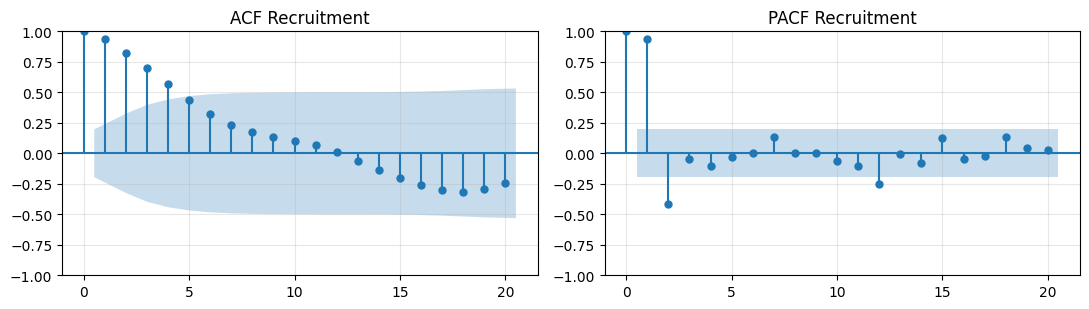


Walk-forward results on 40 out-of-sample points
                             MAE    RMSE   WAPE    Bias   MASE  Dir. acc.  \
model                                                                       
AR(2) rolling              7.051   8.489  0.155   1.579  1.099      0.600   
Last value (persistence)   7.696   9.506  0.169   1.485  1.199        NaN   
Window mean               26.176  29.371  0.576  12.866  4.079      0.525   

                          Rel. RMSE vs persistence  
model                                               
AR(2) rolling                                0.893  
Last value (persistence)                     1.000  
Window mean                                  3.090  

Diebold-Mariano, AR(2) vs persistence: stat = -1.505, p = 0.1405 (negative = AR(2) better)


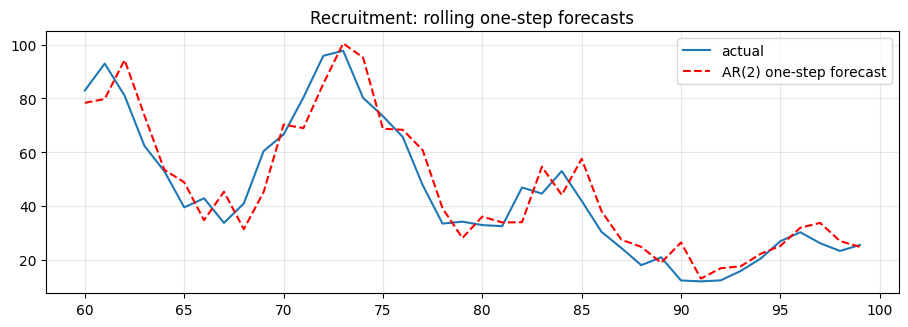

In [16]:
rec = np.array("""
68.63 68.63 68.63 68.63 68.63 68.63 59.16 48.70 47.54 50.91 44.70 42.85 39.62 44.45 38.98 42.62
48.27 59.39 51.66 38.55 60.33 72.27 68.62 69.63 72.20 67.87 64.91 53.85 37.96 23.23 12.68 9.84
7.82 11.78 10.22 12.19 18.60 26.97 22.52 19.18 17.14 18.61 20.02 22.65 38.99 76.55 87.99 99.80
96.69 87.45 88.57 97.43 99.99 94.88 86.99 79.73 92.35 91.29 94.31 84.95 82.97 92.98 81.06 62.37
52.99 39.53 42.90 33.76 40.97 60.50 66.61 80.38 95.86 97.74 80.24 73.44 65.67 47.81 33.51 34.22
32.95 32.55 46.92 44.64 53.02 41.98 30.43 24.43 18.05 20.98 12.37 12.03 12.41 15.89 20.46 26.95
30.29 26.21 23.34 25.55
""".split(), float)
print(f"Recruitment: n={len(rec)}, mean={rec.mean():.2f}, variance={rec.var(ddof=1):.1f}")
acf_pacf_plot(rec, 20, "Recruitment")

W, st = 50, 60
pred_ar2 = rolling_arima(rec, (2, 0, 0), W, st, refit_every=5)
pred_last = rec[st-1:-1]                                           # yesterday's value
pred_m = np.array([rec[i-W:i].mean() for i in range(st, len(rec))])
act = rec[st:]; prev = rec[st-1:-1]; sc = np.mean(np.abs(np.diff(rec[:st])))

rows = [forecast_metrics(act, p, n, sc, prev) for p, n in
        [(pred_ar2, "AR(2) rolling"), (pred_last, "Last value (persistence)"), (pred_m, "Window mean")]]
out = pd.DataFrame(rows).set_index("model")
out["Rel. RMSE vs persistence"] = out["RMSE"] / out.loc["Last value (persistence)", "RMSE"]
print(f"\nWalk-forward results on {len(act)} out-of-sample points"); print(out.round(3))
s2, p2 = dm_test(act - pred_ar2, act - pred_last)
print(f"\nDiebold-Mariano, AR(2) vs persistence: stat = {s2:.3f}, p = {p2:.4f} (negative = AR(2) better)")
rel_rmse_rec = out.loc["AR(2) rolling", "Rel. RMSE vs persistence"]; dm_rec_p = p2
plt.plot(range(st, len(rec)), act, label="actual"); plt.plot(range(st, len(rec)), pred_ar2, "r--", label="AR(2) one-step forecast")
plt.legend(); plt.title("Recruitment: rolling one-step forecasts"); plt.show()

**Reading the results.** Direction is measured as the sign of the *change* from yesterday, since the series is always positive. The gain over persistence is modest because a highly persistent series makes "same as yesterday" hard to beat. With only 40 test points, check the Diebold-Mariano p-value before reading much into the size of the gain.

## 12. Results summary, limitations and next steps
The summary below is generated from the objects computed above, so the numbers always match the data that was loaded.

In [17]:
def verdict(rel, p, alpha=0.05):
    if p < alpha: return "significantly " + ("better than" if rel < 1 else "worse than")
    return "not statistically distinguishable from"

print(f"Data source        : {DATA_SOURCE}")
print(f"Out-of-sample span : {test.index[0].date()} to {test.index[-1].date()} ({len(test)} days), window={WINDOW}, refit every {REFIT_EVERY}d\n")
lb10_p = acorr_ljungbox(log_ret, lags=[10])["lb_pvalue"].iloc[0]
print(f"1. Return autocorrelation: largest |ACF| over lags 1-20 = {np.abs(a20).max():.3f} (white-noise band +/-{band:.3f}); "
      f"Ljung-Box p (10 lags) = {lb10_p:.1e}; lag-1 autocorrelation {r1_all:+.3f} full sample vs {r1_ex:+.3f} excluding Feb-Jun 2020.")
print("2. " + ("Volatility clustering is present" if lm_p < 0.05 else "No evidence of volatility clustering") + f" (ARCH-LM p = {lm_p:.1e}).")
print(f"3. ARIMA{best} relative RMSE vs zero forecast = {rel_rmse_arima:.4f}; {verdict(rel_rmse_arima, dm_arima_zero_p)} the zero forecast (DM p = {dm_arima_zero_p:.3f}).")
c90 = cov_tab.loc[("90%", "constant width")]; v90 = cov_tab.loc[("90%", "vol-scaled")]
print(f"4. 90% intervals: constant-width coverage {c90['coverage']:.1%} (low/high vol: {c90['cov. low vol']:.1%} / {c90['cov. high vol']:.1%}) "
      f"vs vol-scaled {v90['coverage']:.1%} ({v90['cov. low vol']:.1%} / {v90['cov. high vol']:.1%}); "
      f"interval score {c90['interval score']:.4f} vs {v90['interval score']:.4f}.")
print(f"5. Contrast series: AR(2) RMSE is {abs(1 - rel_rmse_rec):.1%} {'lower' if rel_rmse_rec < 1 else 'higher'} than persistence "
      f"(relative RMSE {rel_rmse_rec:.3f}); {verdict(rel_rmse_rec, dm_rec_p)} persistence (DM p = {dm_rec_p:.3f}, n = {len(act)} test points).")

Data source        : Yahoo Finance via yfinance (SPY), downloaded 2026-10-14
Out-of-sample span : 2025-01-10 to 2026-10-14 (442 days), window=750, refit every 21d

1. Return autocorrelation: largest |ACF| over lags 1-20 = 0.130 (white-noise band +/-0.042); Ljung-Box p (10 lags) = 3.9e-36; lag-1 autocorrelation -0.130 full sample vs -0.033 excluding Feb-Jun 2020.
2. Volatility clustering is present (ARCH-LM p = 2.1e-134).
3. ARIMA(0, 0, 2) relative RMSE vs zero forecast = 1.0008; not statistically distinguishable from the zero forecast (DM p = 0.829).
4. 90% intervals: constant-width coverage 93.9% (low/high vol: 96.5% / 89.5%) vs vol-scaled 91.2% (90.4% / 93.9%); interval score 0.0379 vs 0.0354.
5. Contrast series: AR(2) RMSE is 10.7% lower than persistence (relative RMSE 0.893); not statistically distinguishable from persistence (DM p = 0.140, n = 40 test points).


### Limitations
- **Single asset, single horizon.** One equity index at a one-day horizon. Multi-step forecasts and other assets may behave differently.
- **Daily returns are near the efficient-market limit.** The result says little about domains with real structure, such as retail demand.
- **Order search is small** (p, q ≤ 3) and the selected order can change with the window. Weak AIC separation means the "best" order is not stable.
- **Interval guarantees are approximate.** Conformal coverage assumes exchangeable calibration scores; regime shifts break this.
- **Diebold-Mariano with 40 points** (Section 11) has low power, and tests assume the loss differential is stationary.
- **No transaction costs or trading rule.** Directional accuracy is not profitability.
- **The data source can change.** Yahoo Finance adjusted prices are revised for dividends and splits, so exact numbers can differ slightly between downloads (see the date in `DATA_SOURCE`).

### Next steps
- Apply the same walk-forward framework to **retail demand data** (e.g. M5): WAPE/MASE/bias by SKU, Croston/ETS baselines for intermittent demand, and a LightGBM global model.
- Replace the EWMA volatility with a fitted **GARCH** model and compare interval quality.
- Evaluate **quantile loss** and calibration of quantile forecasts directly.
- Estimate the **causal effect** of promotions (see the companion notebook on difference-in-differences with a known ground truth).